In [ ]:
import os

In [15]:
def total_files(folder_path):
    num_files = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])
    return num_files

train_files_healthy = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Train\Train\Healthy"
train_files_powdery = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Train\Train\Powdery"
train_files_rust = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Train\Train\Rust"

test_files_healthy = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Test\Test\Healthy"
test_files_powdery = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Test\Test\Powdery"
test_files_rust = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Test\Test\Rust"

valid_files_healthy = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Validation\Validation\Healthy"
valid_files_powdery = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Validation\Validation\Powdery"
valid_files_rust = r"C:\Users\ZaBir\Downloads\Compressed\Dataset\Validation\Validation\Rust"

print("Number of healthy leaf images in training set", total_files(train_files_healthy))
print("Number of powder leaf images in training set", total_files(train_files_powdery))
print("Number of rusty leaf images in training set", total_files(train_files_rust))

print("========================================================")

print("Number of healthy leaf images in test set", total_files(test_files_healthy))
print("Number of powder leaf images in test set", total_files(test_files_powdery))
print("Number of rusty leaf images in test set", total_files(test_files_rust))

print("========================================================")

print("Number of healthy leaf images in validation set", total_files(valid_files_healthy))
print("Number of powder leaf images in validation set", total_files(valid_files_powdery))
print("Number of rusty leaf images in validation set", total_files(valid_files_rust))

Number of healthy leaf images in training set 458
Number of powder leaf images in training set 430
Number of rusty leaf images in training set 434
Number of healthy leaf images in test set 50
Number of powder leaf images in test set 50
Number of rusty leaf images in test set 50
Number of healthy leaf images in validation set 20
Number of powder leaf images in validation set 20
Number of rusty leaf images in validation set 20


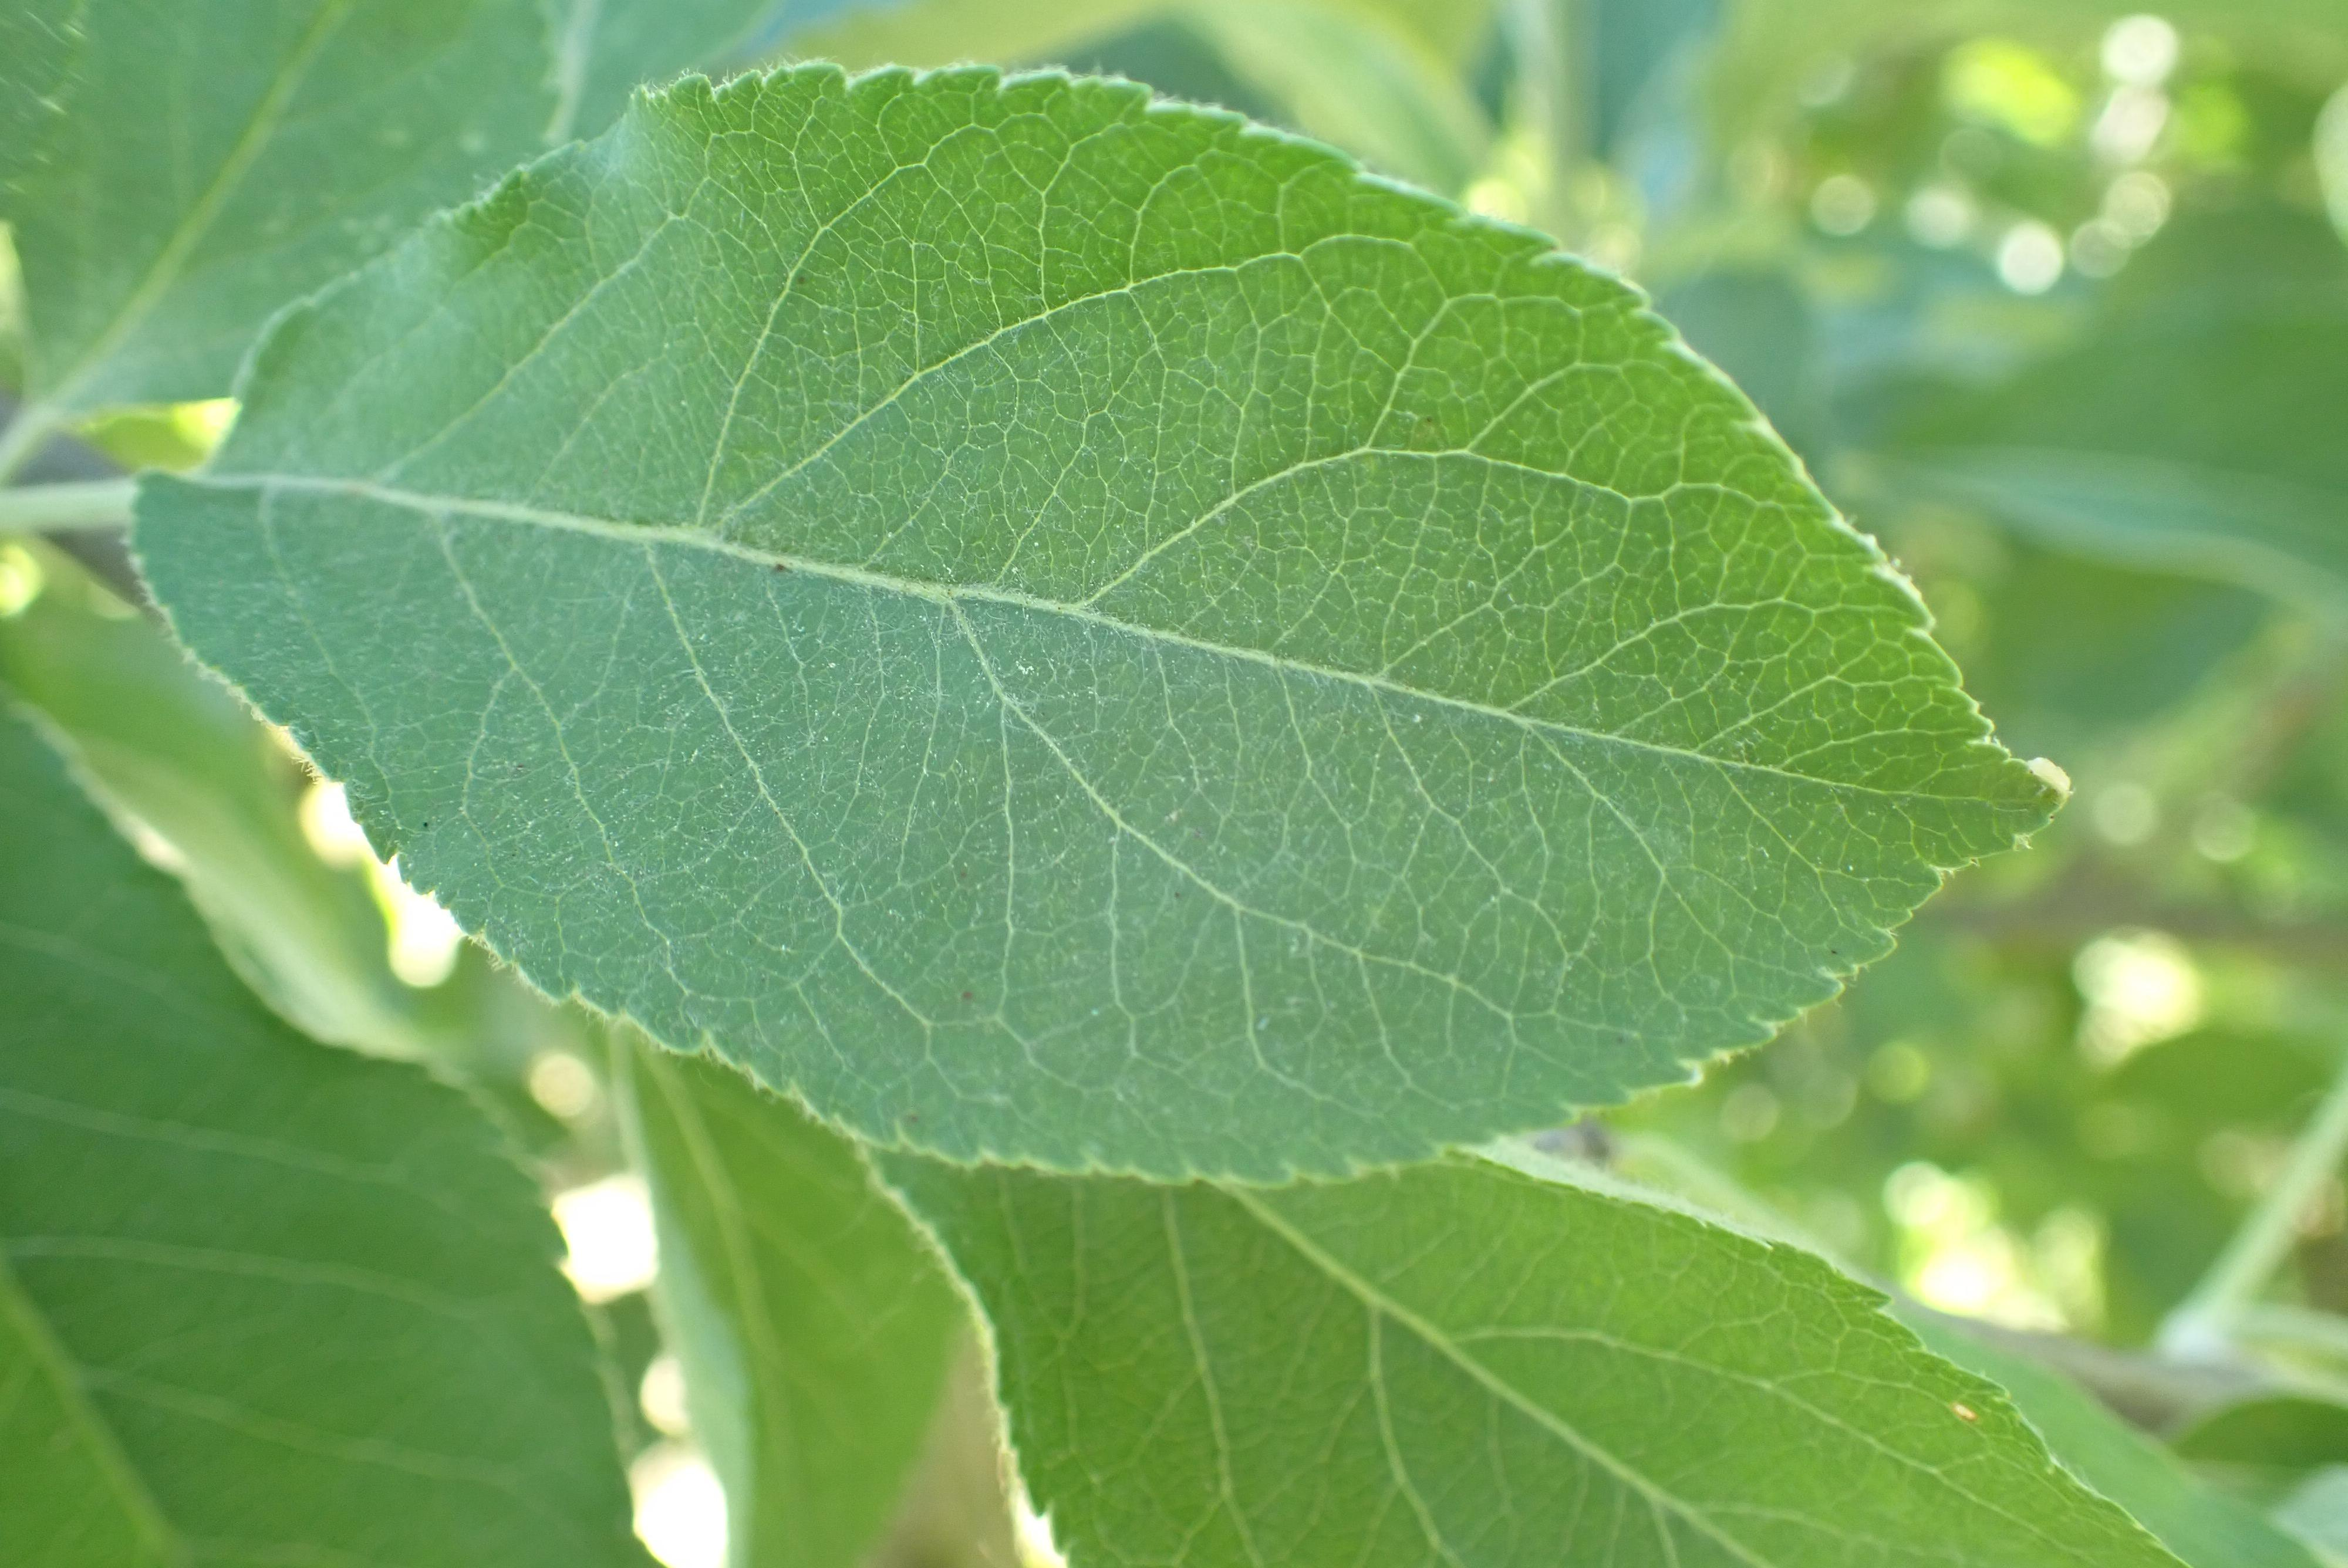

In [16]:
from PIL import Image
import IPython.display as display

image_path = r'C:\Users\ZaBir\Downloads\Compressed\Dataset\Train\Train\Healthy\81f98780ca8fcaed.jpg'

with open(image_path, 'rb') as f:
    display.display(display.Image(data=f.read(), width=500))

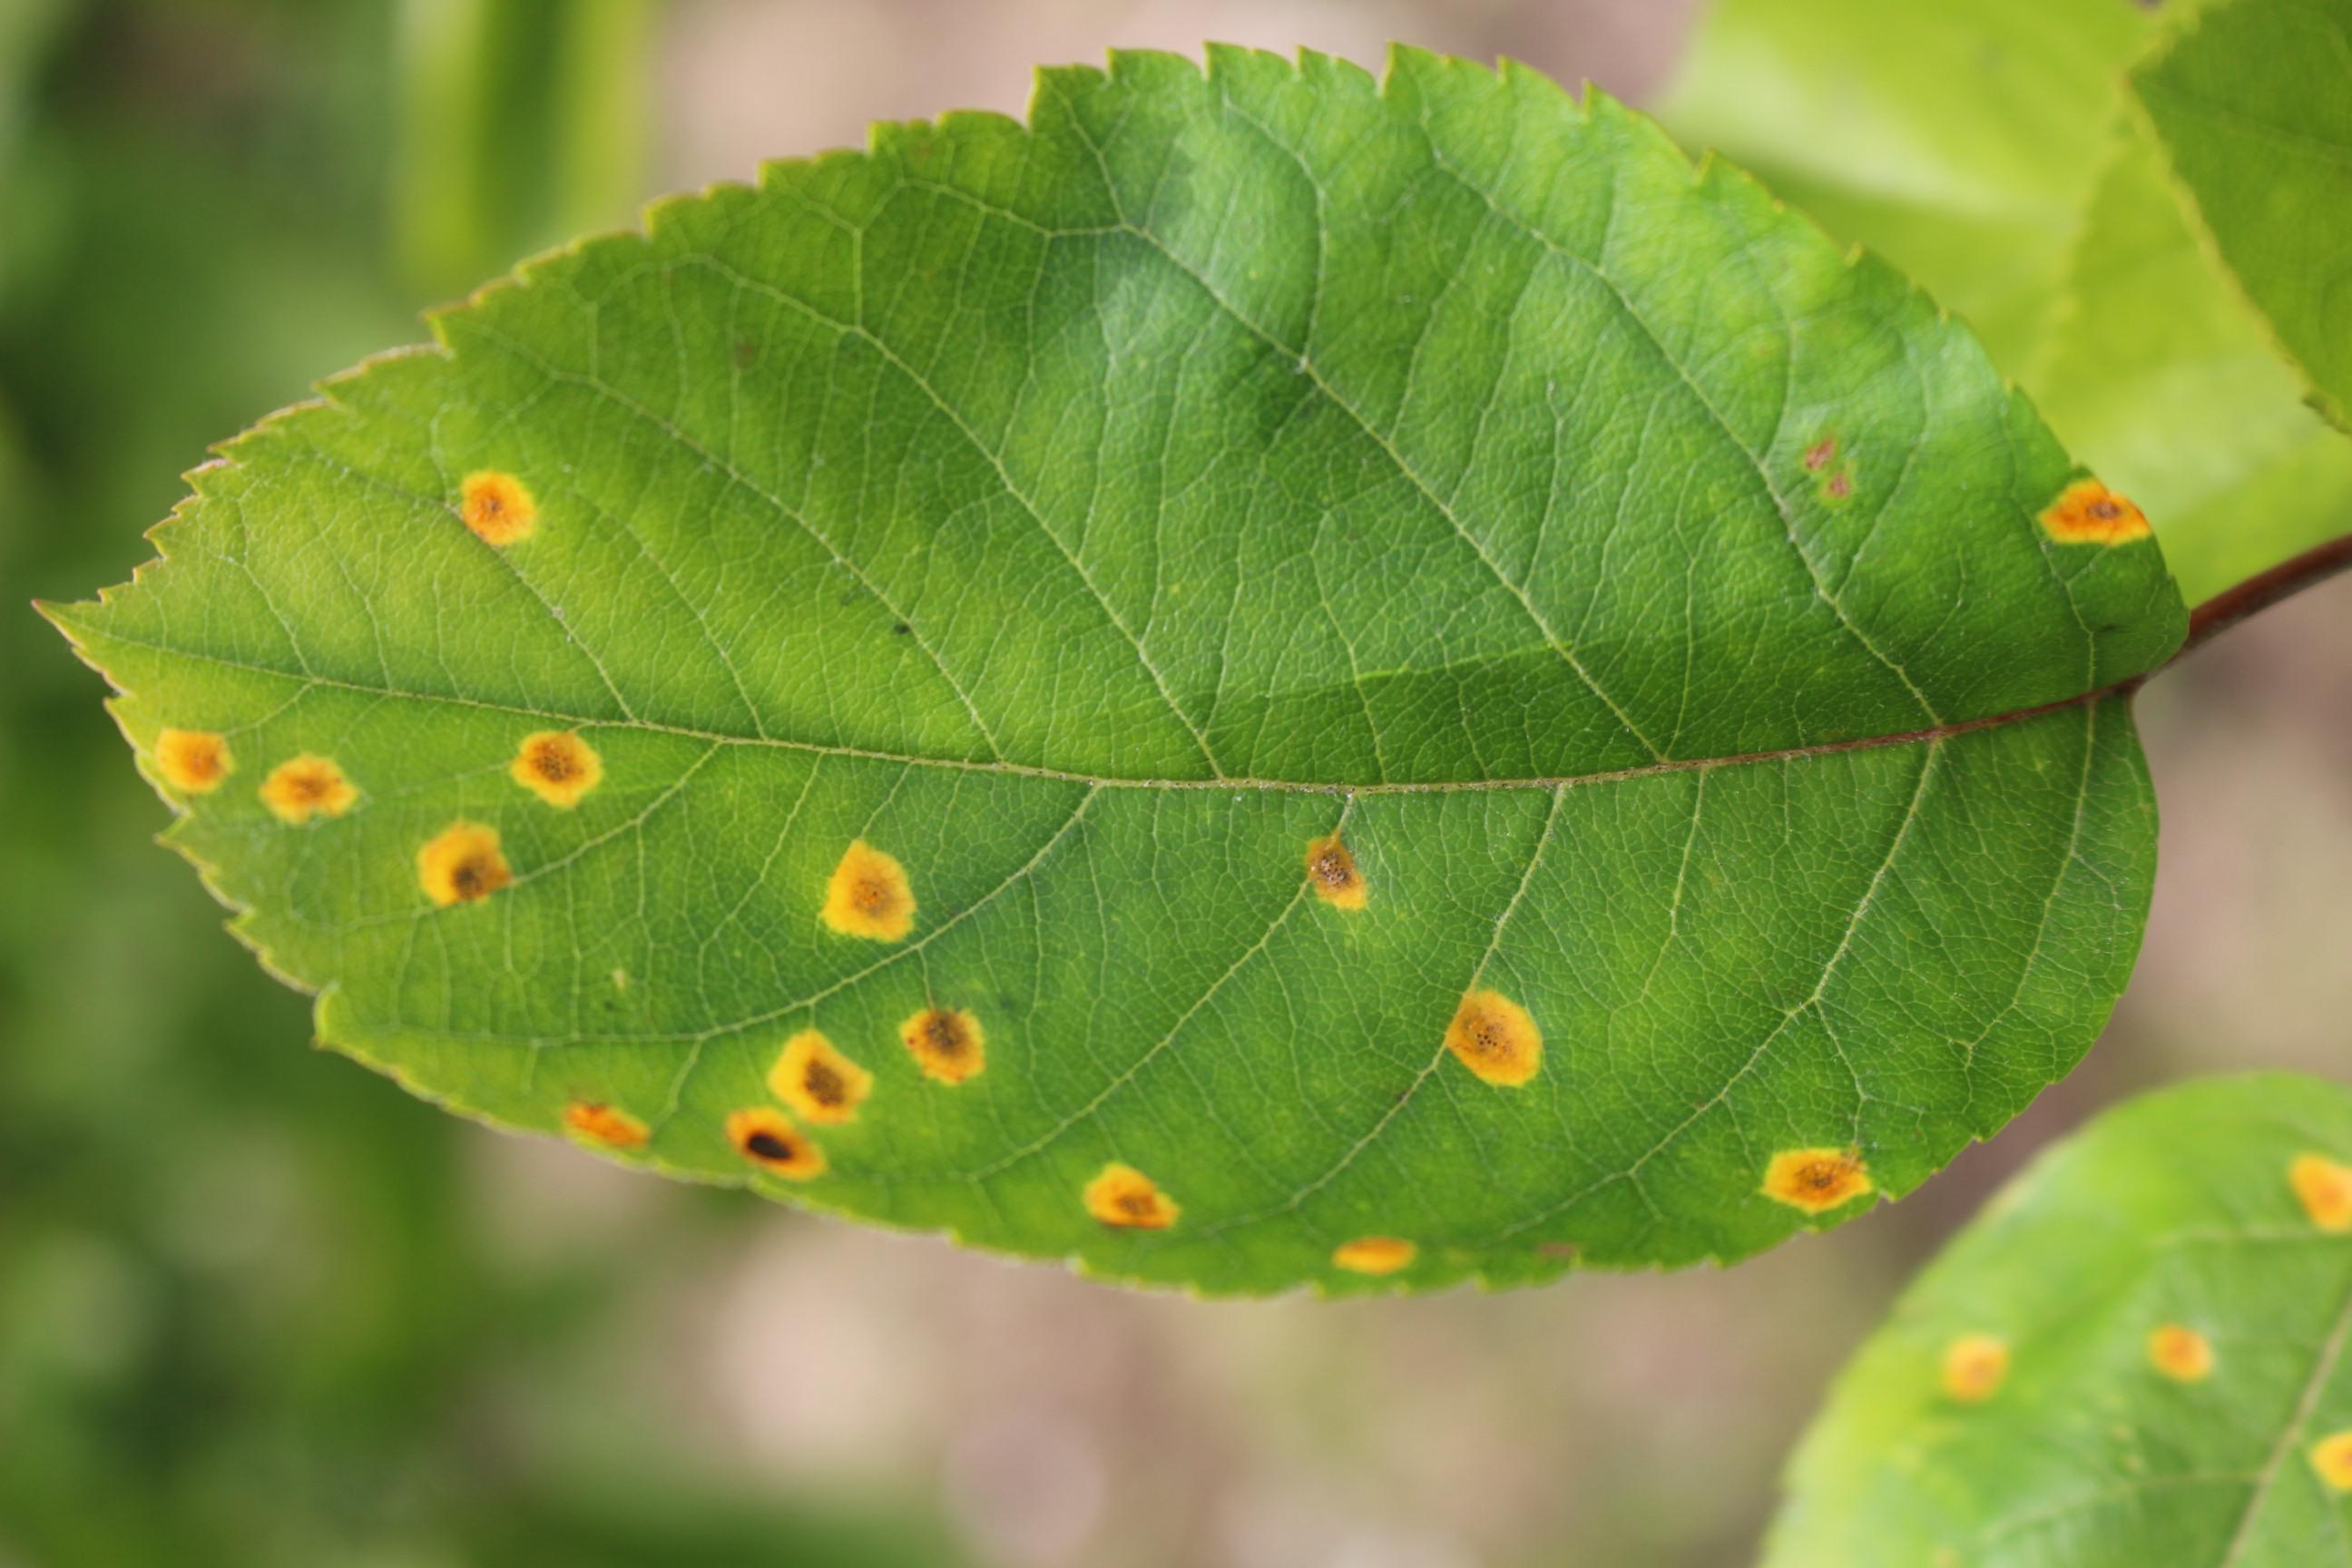

In [17]:
image_path = r'C:\Users\ZaBir\Downloads\Compressed\Dataset\Train\Train\Rust\80f09587dfc7988e.jpg'

with open(image_path, 'rb') as f:
    display.display(display.Image(data=f.read(), width=500))

In [19]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1./255)

In [21]:
train_generator = train_datagen.flow_from_directory(r'C:\Users\ZaBir\Downloads\Compressed\Dataset\Train\Train',
                                                    target_size=(225, 225),
                                                    batch_size=32,
                                                    class_mode='categorical')

validation_generator = test_datagen.flow_from_directory(r'C:\Users\ZaBir\Downloads\Compressed\Dataset\Validation\Validation',
                                                        target_size=(225, 225),
                                                        batch_size=32,
                                                        class_mode='categorical')

Found 1322 images belonging to 3 classes.
Found 60 images belonging to 3 classes.


In [22]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense


model = Sequential()
model.add(Conv2D(32, (3, 3), input_shape=(225, 225, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(3, activation='softmax'))

C:\Users\ZaBir\Python 3.14.10\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [24]:
history = model.fit(train_generator,
                    batch_size=16,
                    epochs=5,
                    validation_data=validation_generator,
                    validation_batch_size=16
                    )

Epoch 1/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.5219 - loss: 1.9232 - val_accuracy: 0.5833 - val_loss: 0.7493
Epoch 2/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.7542 - loss: 0.5659 - val_accuracy: 0.8000 - val_loss: 0.5803
Epoch 3/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.8018 - loss: 0.4504 - val_accuracy: 0.8167 - val_loss: 0.4806
Epoch 4/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.8540 - loss: 0.3708 - val_accuracy: 0.8167 - val_loss: 0.5154
Epoch 5/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.8858 - loss: 0.3171 - val_accuracy: 0.8667 - val_loss: 0.3974


In [25]:
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure

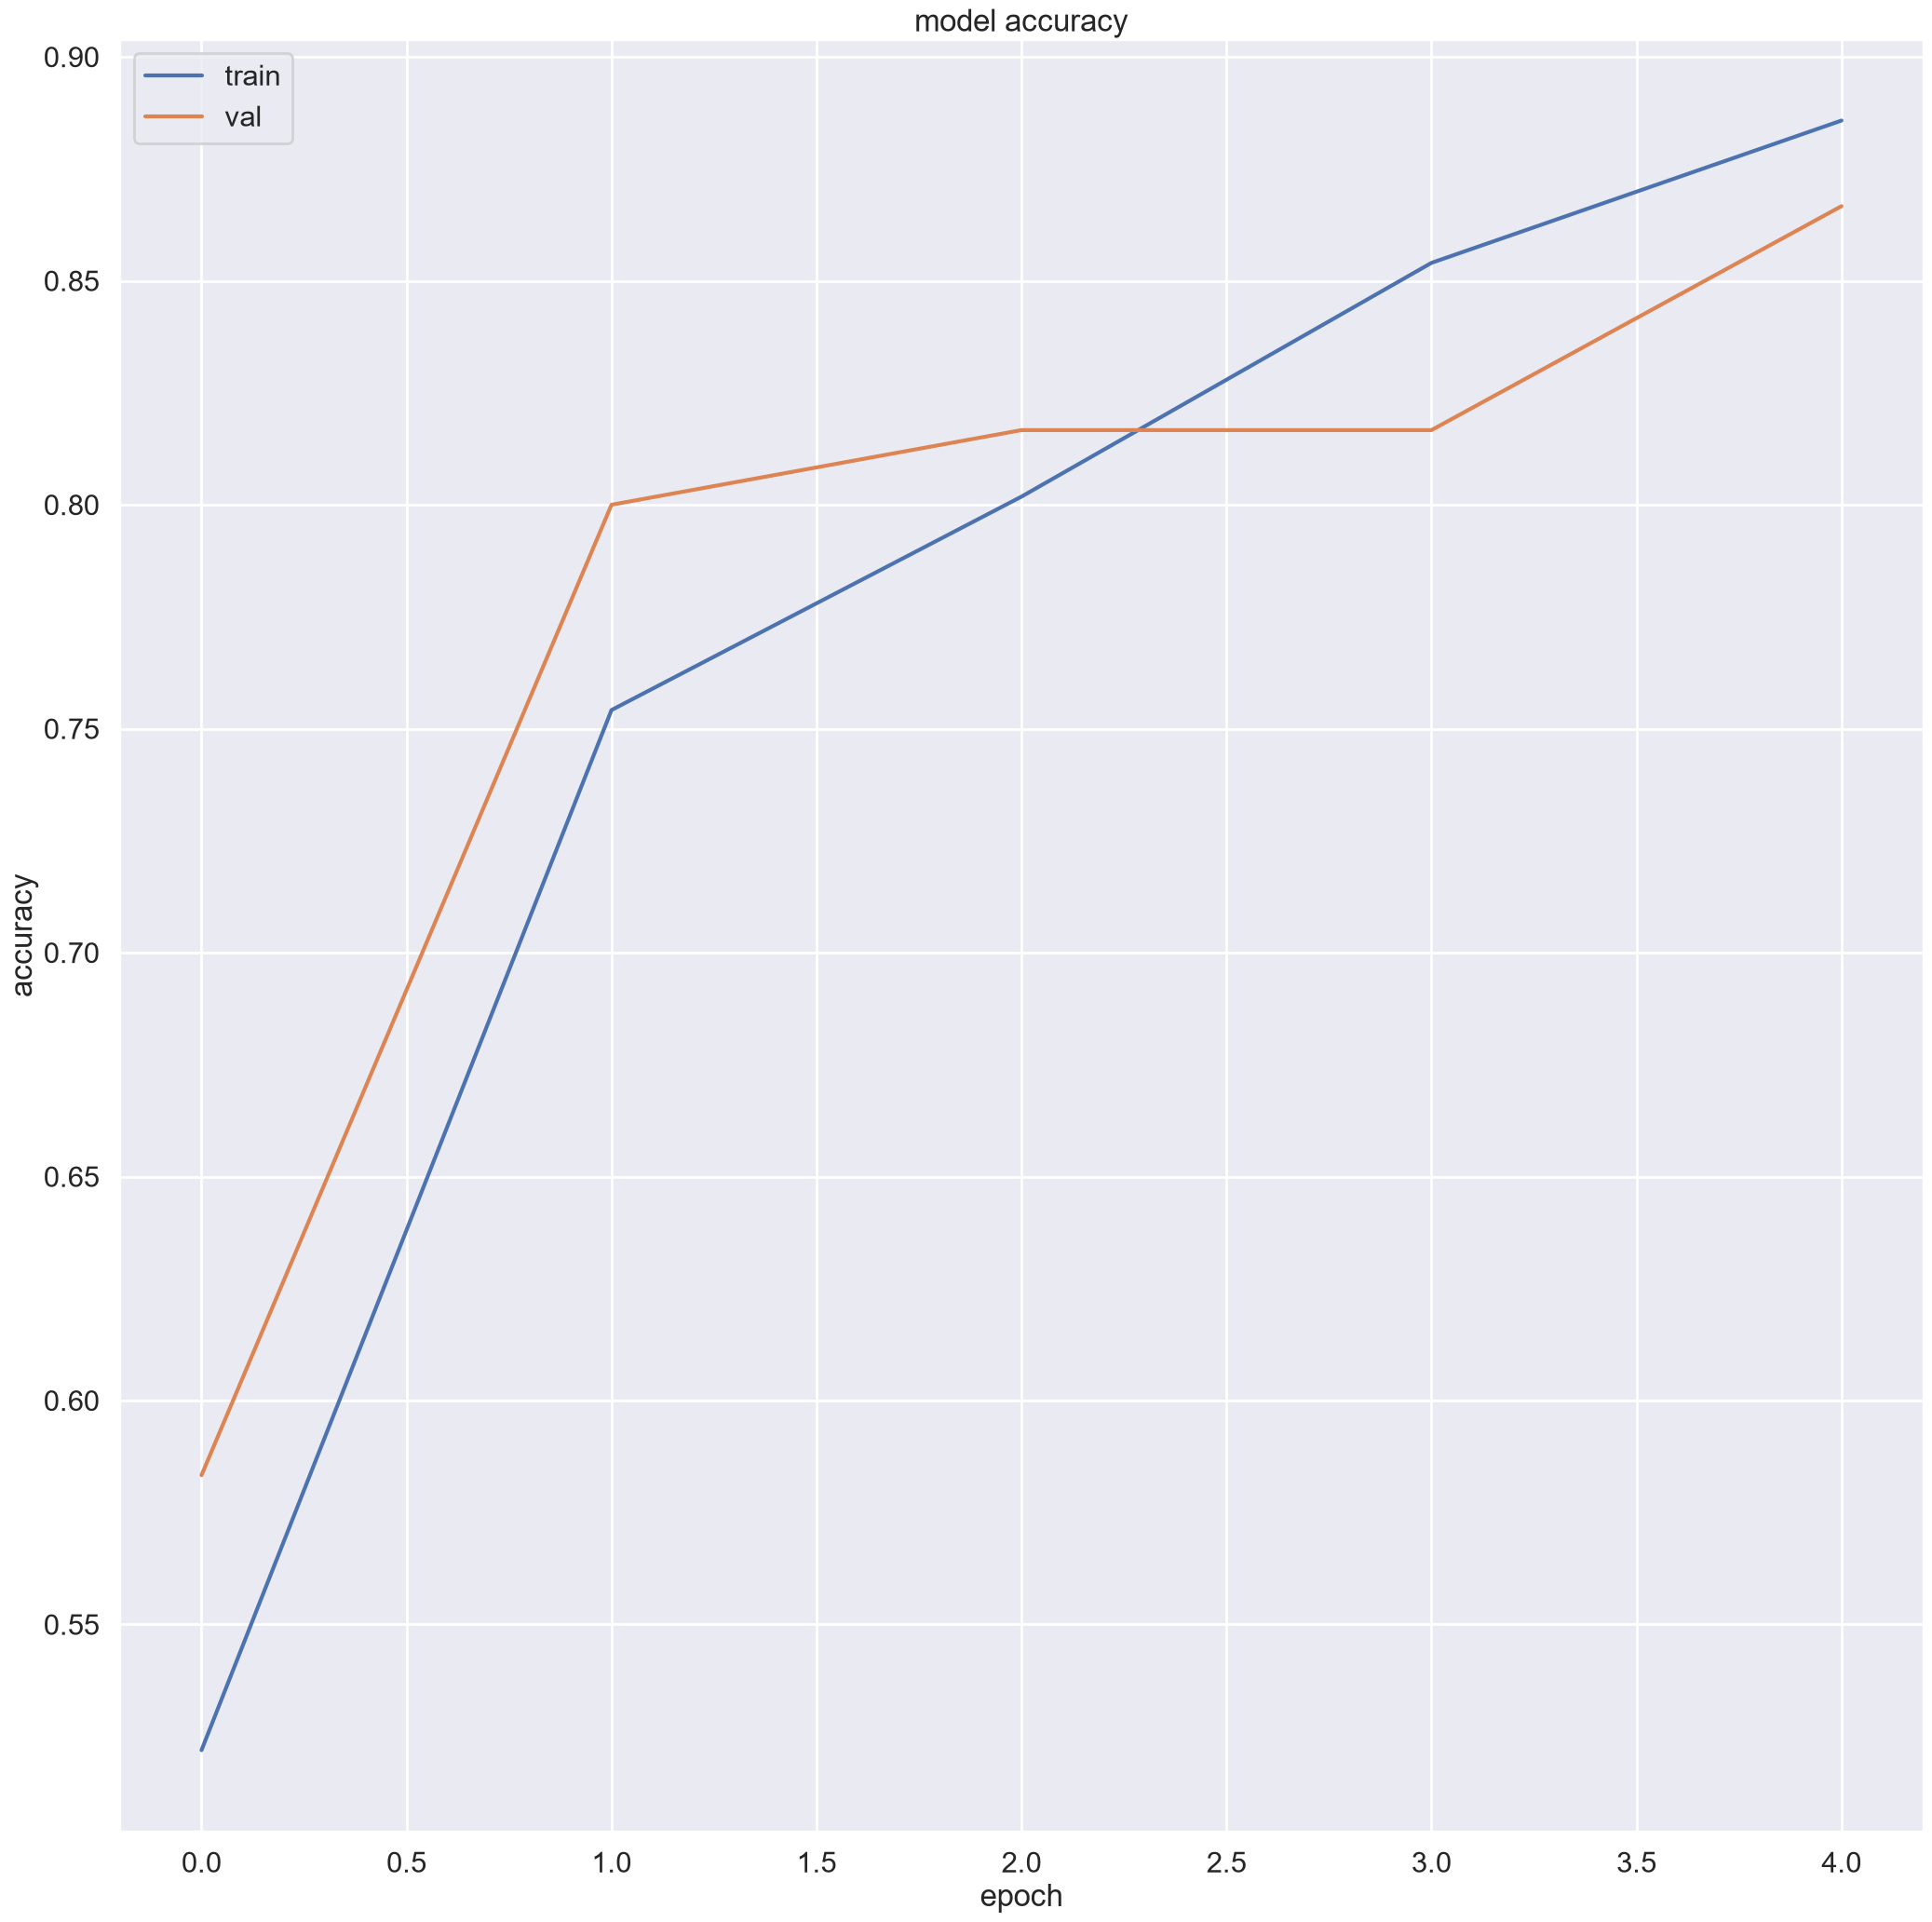

In [26]:
import seaborn as sns
sns.set_theme()
sns.set_context("poster")

figure(figsize=(25, 25), dpi=100)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [35]:
BASE_DIR = r"C:\Users\ZaBir\Desktop\Plant Disease Detection"

model_path = os.path.join(BASE_DIR, "plantdiseasemodel.h5")

model.save(model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: C:\Users\ZaBir\Desktop\Plant Disease Detection\plantdiseasemodel.h5


In [29]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def preprocess_image(image_path, target_size=(225, 225)):
    img = load_img(image_path, target_size=target_size)
    x = img_to_array(img)
    x = x.astype('float32') / 255.
    x = np.expand_dims(x, axis=0)
    return x

x = preprocess_image(r'C:\Users\ZaBir\Downloads\Compressed\Dataset\Test\Test\Rust\82f49a4a7b9585f1.jpg')

In [30]:
predictions = model.predict(x)
predictions[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step


array([2.6121280e-01, 1.3378398e-04, 7.3865342e-01], dtype=float32)

In [31]:
labels = train_generator.class_indices
labels = {v: k for k, v in labels.items()}
labels

{0: 'Healthy', 1: 'Powdery', 2: 'Rust'}

In [32]:
predicted_label = labels[np.argmax(predictions)]
print(predicted_label)

Rust


# ZABIR HASAN